In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using JLD2

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.0011046397057566464 - 0.00010581490510351837im 0.0004414009797804119 - 0.0018357631508163993im … -0.0030886568199521985 + 0.0010590978650101305im 0.0007867738550071137 - 0.0005173890870236106im; 0.002928623682946393 + 0.0002490518975453559im 0.0003647524139814179 + 0.001765800209181656im … -0.00033707431009956607 - 0.0024933010051016876im 0.0038486878263045135 + 0.00041090694581083384im; -0.0008055372613664113 - 0.0005970834371840881im 0.0033365733871548522 - 0.004695347936264878im … 0.002283269506212764 + 0.0007659112245005456im 0.0006802311645327724 - 0.0013517355193154992im;;; 0.005304621657412461 - 0.0028865480964057706im 0.0015141887351618945 - 0.00021271870530933506im … 0.001172431826541622 - 0.000212113093972825im -0.0009556048209235814 + 1.1924545736070773e-5im; -0.003611031449448734 - 0.000334382429859626im 0.002506247080318837 + 0.0011560347218527215im … 0.004365539063471559 - 0.0016069814315366811i

In [3]:
P=Onestep()
hop=Hopping_operator(U,P)
W1=Generate_weight(hop)
W2=Generate_weight(hop)

9-element Vector{Spin_matrix}:
 [-0.7801515364715403 + 0.0im 0.8232856890613126 + 0.0im -0.5855353908568106 + 0.0im -0.03519944160859663 + 0.0im; 0.20461139304504727 + 0.0im -0.8033461953205071 + 0.0im 0.24439508991067543 + 0.0im 0.09703438154625521 + 0.0im; 0.9483789494302818 + 0.0im -1.265519482873207 + 0.0im 0.19107841224323968 + 0.0im -0.6359544877832327 + 0.0im; 0.5998474027730014 + 0.0im -1.6761081180106223 + 0.0im -0.13636970084772868 + 0.0im 1.0150213840451852 + 0.0im]
 [-0.24208549947175242 + 0.0im 0.7006895024973603 + 0.0im -0.3121779573072264 + 0.0im -0.5039272918713406 + 0.0im; 0.21516176391459949 + 0.0im -0.3462171673658826 + 0.0im -0.6316307932718893 + 0.0im 0.4319412505277827 + 0.0im; 0.6035212362521422 + 0.0im -0.2784971102001792 + 0.0im -2.008631902813501 + 0.0im -0.1635439491936696 + 0.0im; 0.22831436043608136 + 0.0im -1.054899093174438 + 0.0im -0.2043924178022868 + 0.0im 0.3050009015508665 + 0.0im]
 [0.2898582265094425 + 0.0im -1.4872105048819673 + 0.0im 0.3410953902

In [4]:
layer1=CPTC_Layer(hop,W1)
layer2=PTC_Layer(hop,W2)
Norm1=NormLayer()
act=Softmax()
layer1=Attention_Layer(layer1,sqrt(length(x)), act, true )
layers=[layer1,Norm1,layer2]
layer1.Q.W=layer1.Q.W*0.01
layer1.K.W=layer1.K.W*0.01
layer1.V.W=layer1.V.W*0.01
layer2.W=layer2.W*0.01
W=load("PTC_weight.jld2","W")
# layer1.Q.W=W
# layer1.K.W=W
# layer1.V.W=W
# layer2.W=W

9-element Vector{Spin_matrix}:
 [0.007797213036129983 + 0.46735840963330766im -0.026578401638403172 + 0.18293037008151905im -0.16598969196948524 + 0.11286190214432579im -0.0988911442072847 - 0.10551336224322834im; -0.1301749861143115 + 0.14964079864516017im -0.08272744488651253 + 0.11694232093281098im -0.0468860012040783 + 0.04693381078173443im -0.10875469415950455 - 0.2717394620408148im; 0.06145145313642434 + 0.1434341923968863im 0.008594680349508183 + 0.03840942730259284im -0.02405890324774394 + 0.06080219969065958im 0.0250090709896045 - 0.12736698608710947im; 0.1208438140841498 - 0.04387786691161287im 0.20168094412363868 - 0.20723624776300223im -0.08729685710280867 - 0.13487692298577159im -0.04015420257836383 + 0.08629890431050874im]
 [0.06449606731584365 + 0.005550198841013663im -0.04833680567489927 + 0.109671899449611im 0.10397530354214761 + 0.040889596398287174im 0.014963313362258503 - 0.07504439800864347im; 0.0021850212245376893 + 0.09376213134525353im 0.045494976640816476 + 0.0

In [5]:
opt=Adam()
opt.α=0.05

0.05

In [6]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[5.668814271331787e-6 - 4.735827158289965e-6im -2.1366300437129208e-6 - 8.08387396872833e-6im … 6.824021831236319e-6 - 2.0018753606839662e-6im -2.0866432182284777e-6 - 6.107144119694354e-6im; 6.290847624350452e-7 + 2.7509084389444592e-6im 7.785397245144448e-7 + 1.0167484368091085e-5im … 9.316712397778201e-6 + 4.348180024863044e-6im 4.806145179638693e-6 + 3.2363332982718664e-6im; -4.191134764045357e-7 - 1.0474178248117025e-5im 4.119271703191026e-6 - 1.812924188173346e-6im … -9.265014874485426e-6 - 8.907809095631401e-6im 4.788876743133961e-7 - 1.981095286708463e-6im;;; -1.8247884933141084e-6 - 6.467367683100204e-6im 1.031514288817498e-8 - 4.585552754119134e-6im … -1.1522060955094094e-6 + 3.203097881489506e-6im -1.155976680809453e-6 + 2.4284085666021132e-6im; -1.8356309647769657e-6 - 9.068595274195939e-6im -3.6083700207244877e-6 - 1.21412361643578e-5im … -3.5969816057140395e-7 - 4.881662455910629e-6im 1.84006438209

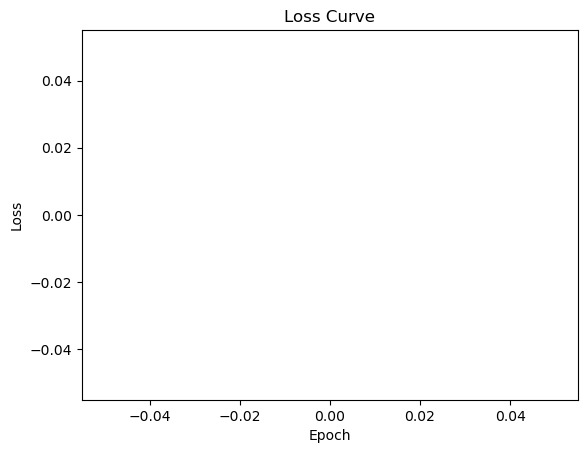

Epoch: 1, Loss: 0.24150055126619016 + 0.0im
Epoch: 2, Loss: 0.4031178635979649 + 0.0im
Epoch: 3, Loss: 0.1678747981928039 + 0.0im
Epoch: 4, Loss: 0.14033201918688248 + 0.0im
Epoch: 5, Loss: 0.20100954787401704 + 0.0im
Epoch: 6, Loss: 0.20630562333094127 + 0.0im
Epoch: 7, Loss: 0.1755632303903051 + 0.0im
Epoch: 8, Loss: 0.14169287846264797 + 0.0im
Epoch: 9, Loss: 0.12143995170621517 + 0.0im
Epoch: 10, Loss: 0.11228384069900445 + 0.0im
Epoch: 11, Loss: 0.11029175016149681 + 0.0im
Epoch: 12, Loss: 0.10873400765667623 + 0.0im
Epoch: 13, Loss: 0.10470824436203326 + 0.0im
Epoch: 14, Loss: 0.09525616084533459 + 0.0im
Epoch: 15, Loss: 0.08649491302363146 + 0.0im
Epoch: 16, Loss: 0.0821327839960034 + 0.0im
Epoch: 17, Loss: 0.08425437047422689 + 0.0im
Epoch: 18, Loss: 0.0849467187848858 + 0.0im
Epoch: 19, Loss: 0.081344328063619 + 0.0im
Epoch: 20, Loss: 0.07554062857106666 + 0.0im
Epoch: 21, Loss: 0.07190341990160788 + 0.0im
Epoch: 22, Loss: 0.06826032005513155 + 0.0im
Epoch: 23, Loss: 0.0649215

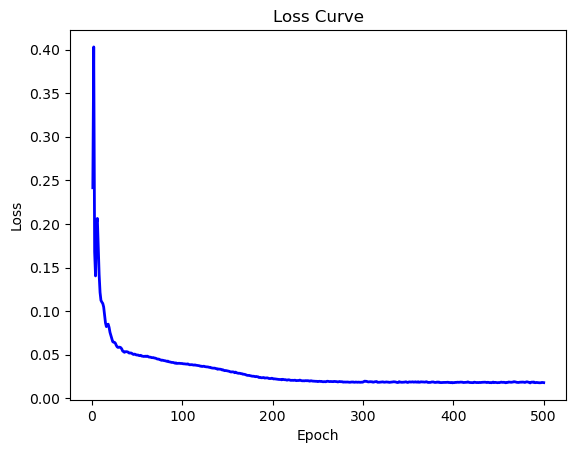

In [7]:
train(opt,layers,x,t,D,epochs=500)